# Lab #2: Probability, Distributions, and Statistical Questions

In [16]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.stats import norm
import scipy.integrate as integrate
import scipy.special as special
from scipy.stats import poisson

## Problem 1
#### Average cosmic-ray background production per day = 7
#### Average number of gamma-rays emmitted by source = 14

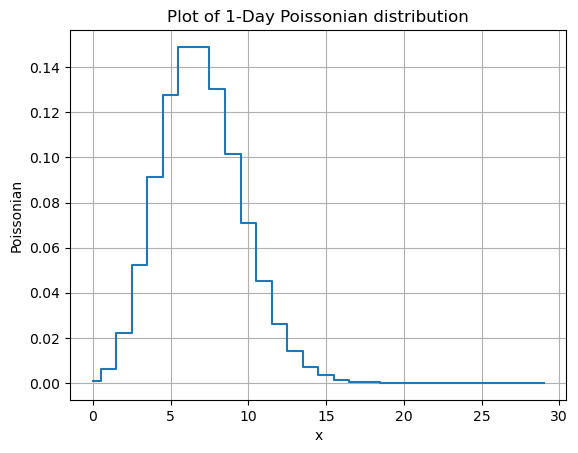

In [19]:
# define poisson distribution for data using 7 noises per day over 1 day
# Noise production * number of days
miu = 7

def poisson(x):
    y = scipy.stats.poisson.pmf(x, miu, loc=0)
    return y   
    
x = np.arange(0, 30)
y = poisson(x)
    
plt.step(x, y, where='mid')
plt.title('Plot of 1-Day Poissonian distribution')
plt.xlabel('x')
plt.ylabel('Poissonian')
plt.grid()
plt.show()

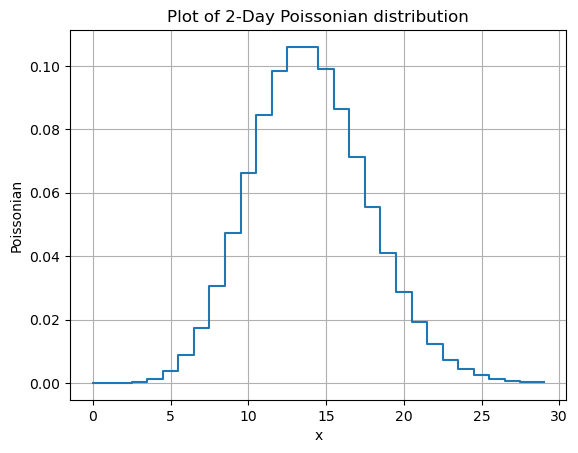

In [5]:
# Poissonian distribution for 7 noises per day, 2 days
def poisson(x):
    y = scipy.stats.poisson.pmf(x, 14, loc=0)
    return y   
    
x = np.arange(0, 30)
y = poisson(x)
    
plt.step(x, y, where='mid')
plt.title('Plot of 2-Day Poissonian distribution')
plt.xlabel('x')
plt.ylabel('Poissonian')
plt.grid()
plt.show()

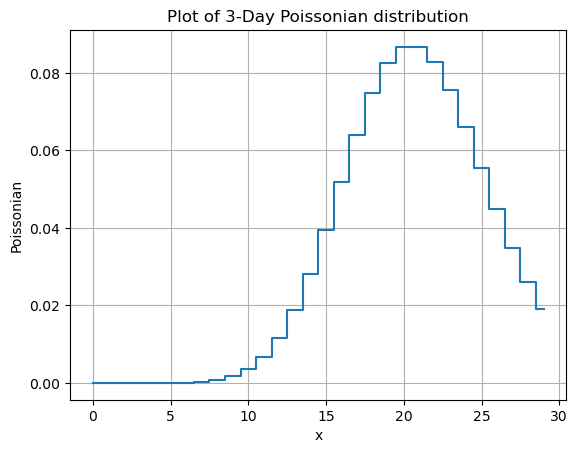

In [6]:
# Poissonian distribution for 7 noises per day, 3 days
def poisson(x):
    y = scipy.stats.poisson.pmf(x, 21, loc=0)
    return y   
    
x = np.arange(0, 30)
y = poisson(x)
    
plt.step(x, y, where='mid')
plt.title('Plot of 3-Day Poissonian distribution')
plt.xlabel('x')
plt.ylabel('Poissonian')
plt.grid()
plt.show()

### Problem 1A: As the number of days for observation increases, the Poissonian simply grows by a multiple amount proportional to the number of additional days of observation.


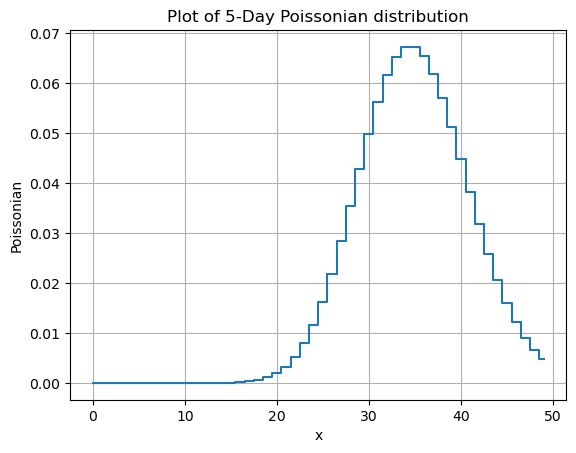

In [7]:
# Poissonian distribution for 7 noises per day, 5 days
def poisson(x):
    y = scipy.stats.poisson.pmf(x, 35, loc=0)
    return y   
    
x = np.arange(0, 50)
y = poisson(x)
    
plt.step(x, y, where='mid')
plt.title('Plot of 5-Day Poissonian distribution')
plt.xlabel('x')
plt.ylabel('Poissonian')
plt.grid()
plt.show()

### Problem 1B: The 5-Day Poissonian distribution is still Poissonian! It's sliding over. This makes sense because the Poissonian's definition is a function of e. Integrating, deriving, and multiplying functions of e does not change the base functionality, only the magnitude of the function. It retains the same form.

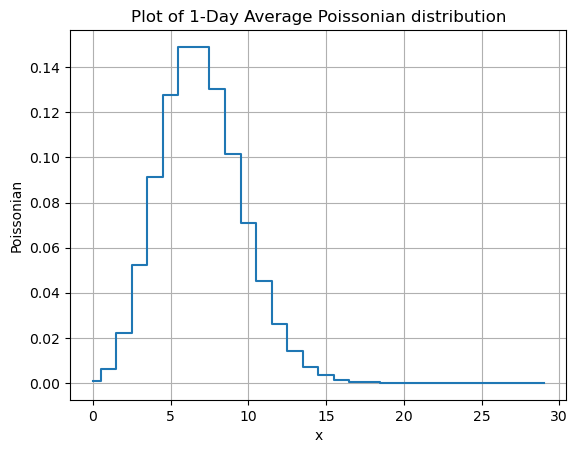

In [8]:
#Problem 1C: Show how the probability distribution function evolves as you average days

# Average noise production for 1 day of observation
def poisson(x):
    y = scipy.stats.poisson.pmf(x, 7, loc=0)
    return y   
    
x = np.arange(0, 30)
y = poisson(x) / 1
    
plt.step(x, y, where='mid')
plt.title('Plot of 1-Day Average Poissonian distribution')
plt.xlabel('x')
plt.ylabel('Poissonian')
plt.grid()
plt.show()

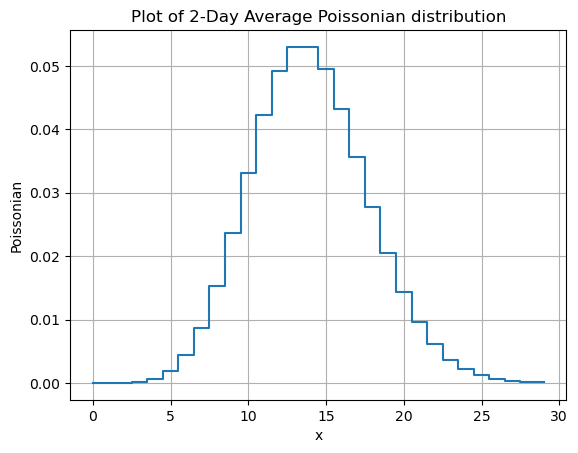

In [9]:
#Problem 1C: Show how the probability distribution function evolves as you average days

# Average noise production for 2 day of observation

def poisson(x):
    y = scipy.stats.poisson.pmf(x, 14, loc=0)
    return y   
    
x = np.arange(0, 30)
y = poisson(x) / 2
    
plt.step(x, y, where='mid')
plt.title('Plot of 2-Day Average Poissonian distribution')
plt.xlabel('x')
plt.ylabel('Poissonian')
plt.grid()
plt.show()

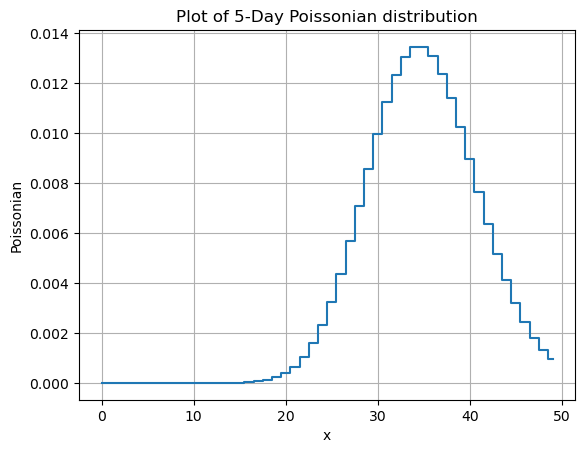

In [10]:
# Average Poissonian distribution for 7 noises per day, 5 days
def poisson(x):
    y = scipy.stats.poisson.pmf(x, 35, loc=0)
    return y   
    
x = np.arange(0, 50)
y = poisson(x) / 5
    
plt.step(x, y, where='mid')
plt.title('Plot of 5-Day Poissonian distribution')
plt.xlabel('x')
plt.ylabel('Poissonian')
plt.grid()
plt.show()

### Problem 1C: It seems that the average of the Poissonian over multiple days evolves similarly to the Poissonian itself. Now, it's simply scaled down by its averaging factor

In [11]:
#Problem 1D: Pick N days, and assume you observed Y*N signals. Calculate the sigma of your observations.
# N = 5, Y = 14
# Signals observed, Y*N = 70
# Use cdf on the test distribution then, ppf on a normal distribution
# The probability will be (1 - the integral of the probability function from -infinity to 14*N)

resulta = stats.poisson.cdf(70, 7, 0)
resultb = 1-resulta
print('The percent chance that the background showed the observations is', resultb)

#Use the ppf function on a Gaussian distribution to find the sigma value of the result
resultc = stats.norm.ppf(resulta, loc=0, scale=1)
print("This corresponds to a sigma value of", resultc)

The percent chance that the background showed the observations is 0.0
This corresponds to a sigma value of inf


### Problem 1D Gold (or pyrite) has been struck
#### These values indicate that the background all but certainly did not produce the signals observed. Therefore, we either genuinely detected a Gamma Ray Burst, or somebody shined a little laser pointer directly into the detector for 5 days.

## Problem 2 

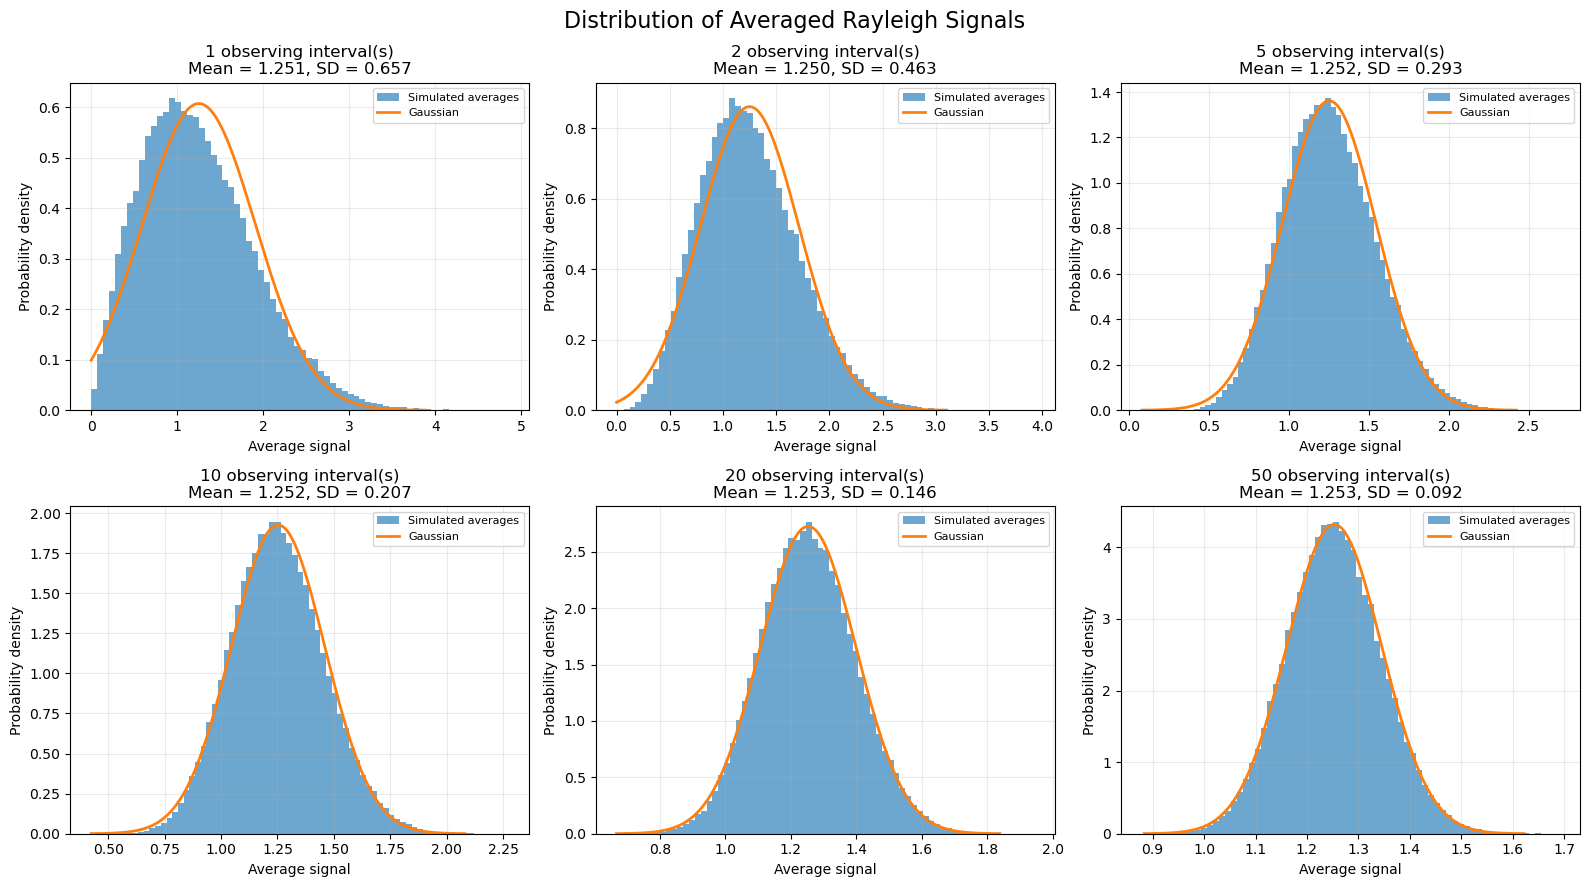

In [18]:
# Show how the Rayleigh distribution changes over an increasing number of observing intervals
# Prediction: according to the Central Limit Theorem, a greater number of observing intervals will lead to
# the convolved distributions becoming mroe and more Gaussian

# Fix a random seed so that the following experiment is reproducible
rng = np.random.default_rng(42)

# Set the scale parameter for the Rayleigh distribution 
scale = 1.0

# Set the number of independent groups of observations to simulate
number_of_groups = 100_000

# Set the numbers of observing intervals to compare
interval_counts = [1, 2, 5, 10, 20, 50]

# Generate Rayleigh-distributed observations (aka the bakcground)
# Each row represents one group of observations
# Each column represents a different observing interval

rayleigh_observations = rng.rayleigh(
    scale=scale,
    size=(number_of_groups, max(interval_counts))
)


# Create six plots arranged in two rows and three columns
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Convert the array of axes into a one-dimensional array
axes = axes.ravel()

# Repeat the plotting process for each number of intervals
for ax, n_intervals in zip(axes, interval_counts):

    # Calculate the average signal for each simulated group, where axis=1 means we average across the observing intervals
    averaged_signal = np.mean(
        rayleigh_observations[:, :n_intervals],
        axis=1
    )

    # Calculate the simulated mean and standard deviation
    simulated_mean = np.mean(averaged_signal)
    simulated_std = np.std(averaged_signal)

    # Plot a normalized histogram of the averaged signals
    ax.hist(
        averaged_signal,
        bins=70,
        density=True,
        alpha=0.65,
        label="Simulated averages"
    )
    
# Set up a Gaussian curve to overlay for comparison
# Generate x-values spanning the main part of the distribution
    x_values = np.linspace(
        max(0, simulated_mean - 4 * simulated_std),
        simulated_mean + 4 * simulated_std,
        500
    )

# Calculate a Gaussian probability density with the same mean and standard deviation as the simulated averages
    gaussian_curve = norm.pdf(
        x_values,
        loc=simulated_mean,
        scale=simulated_std
    )

# Plot the Gaussian curve for comparison
    ax.plot(
        x_values,
        gaussian_curve,
        linewidth=2,
        label="Gaussian"
    )

# Add titles and axis labels for each plot
    ax.set_title(
        f"{n_intervals} observing interval(s)\n"
        f"Mean = {simulated_mean:.3f}, "
        f"SD = {simulated_std:.3f}"
    )

    ax.set_xlabel("Average signal")
    ax.set_ylabel("Probability density")

# Add a legend and grid to each plot
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

# Add an overall title and adjust the spacing of the plots
fig.suptitle(
    "Distribution of Averaged Rayleigh Signals",
    fontsize=16
)

fig.tight_layout()
plt.show()

### Problem 2 continued
#### These graphs illustrate the Central Limit Theorem well as you read from left to right, and then from top to bottom. The graphs plot the Rayleigh distribution of 1, 2, 5, 10, 20, and 50 observing intervals, respectively. Overlaid on these plots are Gaussian curves with the same means and standard deviations as the Rayleighs below them. As the number of observing intervals increases, the convolved Rayleighs adopt the form of the Gaussians. CLT satisfied baby

## Problem 3: Multi Messenger Detections
### A); Version 1

In [25]:
# Pick value for X, aka the measured value of the constant-width Gaussian
sigma = 5.0

# Pick floating-point value for Y, aka the observed signal strength
signal = 5.9

# Use cdf on the test distribution 
# The probability will be (1 - the integral of the probability function from -infinity to signal)
resulta = stats.norm.cdf(signal, loc=0, scale=sigma)
resultb = 1-resulta
print('The percent chance that the background showed the observations is', resultb)

# Then, ppf on a normal distribution
# Use the ppf function on a Gaussian distribution to find the sigma value of the result
resultc = stats.norm.ppf(resulta, loc=0, scale=1)
print("This corresponds to a sigma value of", resultc)

The percent chance that the background showed the observations is 0.11900010745520073
This corresponds to a sigma value of 1.1799999999999997


### Problem 3 continued
#### The sigma value here of approximately 1.18 is not sufficient to claim a discovery. This makes sense - my background width was 5 and my signal value was 5.9, which isn't much greater than the background. BEcause the disparity is low, the signifcance is also low. No dice.
#### I'm going to copt and paste this cell below with a greater difference between the background and signal values just to see the difference

In [26]:
# Pick value for X, aka the measured value of the constant-width Gaussian
sigma = 3.0

# Pick floating-point value for Y, aka the observed signal strength
signal = 8.9

# Use cdf on the test distribution 
# The probability will be (1 - the integral of the probability function from -infinity to signal)
resulta = stats.norm.cdf(signal, loc=0, scale=sigma)
resultb = 1-resulta
print('The percent chance that the background showed the observations is', resultb)

# Then, ppf on a normal distribution
# Use the ppf function on a Gaussian distribution to find the sigma value of the result
resultc = stats.norm.ppf(resulta, loc=0, scale=1)
print("This corresponds to a sigma value of", resultc)

The percent chance that the background showed the observations is 0.0015052357320661791
This corresponds to a sigma value of 2.9666666666666655


#### That's a bigger sigma alright. Still above the 5 sigma threshold, so not quite a detection. 
#### Question: given the same problem, say you ended up with a sigma value of 4.5. What would a scientist make of that?
#### I guess I'm wondering what the significance of 5 sigma is. If I recall correctly, an event occurring at a sigma value of 5 is like saying that said event is a 1/(10^5) occurence?

## Problem 3 continued
### Version 2
#### B): You have 10,000 pixels. Each pixel has a background noise given by a Guassian distribution of constant width (X = 5) and center 0. One of these pixels demonstrates a signal (Y = 5.9). The *overall* background signal is the Gaussian convolved 10^4 times 
#### I don't know if I've restated the objective here as called for, or if what I have stated is even right. I'm thrown by the wording of the question. I do feel that I can picture the situation, despite that. I'll try to code it up 

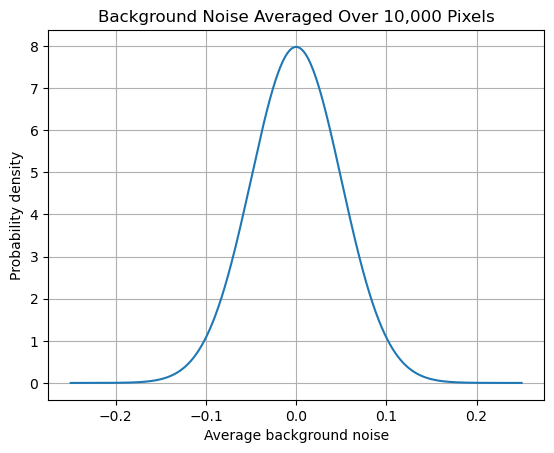

Standard deviation of one interval: 5.0
Standard deviation of the average: 0.05


In [28]:
# Background noise of constant width Gaussian aka standard deviation of one pixel
sigma = 5.0

# Number of independent observing pixels
N = 10_000

# Define standard deviation of the entire background
sigma_average = sigma / np.sqrt(N)

# Set the values over which to plot the probability density
x = np.linspace(-0.25, 0.25, 1000)

# Probability density of the averaged background
pdf_average = stats.norm.pdf(
    x,
    loc=0,
    scale=sigma_average
)

# Plot the result
plt.plot(x, pdf_average)
plt.xlabel("Average background noise")
plt.ylabel("Probability density")
plt.title("Background Noise Averaged Over 10,000 Pixels")
plt.grid()
plt.show()

print("Standard deviation of one interval:", sigma)
print("Standard deviation of the average:", sigma_average)

### 3B continued
#### Instead of convolving the Gaussian 10k times in order to numerically produce the entire background, I defined it in one go. This works for two reasons: firstly, we know the form of the full background will be Gaussian because it's a convolution of many Gaussians. Secondly, we can determine the characteristics of that final Gaussian simply by averaging the standard deviations according to the 1/(N^1/2) scaling. In other words, the averaged standard deviation of 10,000 Gaussians is the initial standard deviation divided by the square root of 10,000 (translates into 5/100, 0.05)
#### Way better than trying to "np.convolve" many many times. I got stuck trying to do that for a good half-hour

### Problem 3C

In [31]:
# Background noise of constant width Gaussian aka standard deviation of one pixel
sigma = 5.0

# Number of independent observing pixels
N = 10_000

# Define standard deviation of the entire background
sigma_average = sigma / np.sqrt(N)

# Set the values over which to plot the probability density
x = np.linspace(-0.25, 0.25, 1000)

# Probability density of the averaged background
pdf_average = stats.norm.pdf(
    x,
    loc=0,
    scale=sigma_average
)

# Pick floating-point value for Y, aka the observed signal strength
signal = 5.9

# Use cdf on the test distribution. The probability will be (1 - the integral of the probability function)

resulta = stats.norm.cdf(signal, 0, sigma_average)
resultb = 1-resulta
print('The percent chance that the background showed the observations is', resultb)

#Use the ppf function on a Gaussian distribution to find the sigma value of the result
resultc = stats.norm.ppf(resulta, loc=0, scale=1)
print("This corresponds to a sigma value of", resultc)

The percent chance that the background showed the observations is 0.0
This corresponds to a sigma value of inf


#### Problem 3C conclusion: it seems that we've got a significant signal. I believe this counts as a detection

## Problem 4

In [34]:
# 4A Calculate the strength of the signal that would yield a sigma of 5 given the same setup as Problem 3 Version 1
# .cdf on a sigma=1 Gaussian, .ppf on the observed Gaussian
# Background noise distribution values
mu = 0
sigma = 5.0

# Cumulative probability corresponding to 5 standard deviations
probability = stats.norm.cdf(5, loc=0, scale=1)

# Find the signal strength at that probability
signal_strength = stats.norm.ppf(
    probability,
    loc=mu,
    scale=sigma
)

print("Required signal strength:", signal_strength)

Required signal strength: 24.99999999985088


In [35]:
# 4B Calculate the strength of the signal that would yield a sigma of 5 given the same setup as Problem 3 Version 2
# .cdf on a sigma=1 Gaussian, .ppf on the observed Gaussian
# Background noise distribution values 
mu = 0
averaged_sigma = 0.05

# Cumulative probability corresponding to 5 standard deviations
probability = stats.norm.cdf(5, loc=0, scale=1)

# Find the signal strength at that probability
signal_strength = stats.norm.ppf(
    probability,
    loc=mu,
    scale=averaged_sigma
)

print("Required signal strength:", signal_strength)

Required signal strength: 0.2499999999985088


### 4C 
#### It seems that the signal strength scales with the inverse square root of the trials factor - .25 is 1/100th of 25. sqrt(10^4) is 10^2
#### The sensitivity penalty due to the trials factor is such a small number because it scales inversely to the trials factor

In [36]:
# 4D Trials factor now 10^8
# .cdf on a sigma=1 Gaussian, .ppf on the observed Gaussian
# Background noise distribution values 
mu = 0
averaged_sigma = 0.0005

# Cumulative probability corresponding to 5 standard deviations
probability = stats.norm.cdf(5, loc=0, scale=1)

# Find the signal strength at that probability
signal_strength = stats.norm.ppf(
    probability,
    loc=mu,
    scale=averaged_sigma
)

print("Required signal strength:", signal_strength)

Required signal strength: 0.002499999999985088


#### 4D With a trials factor of 10^8, the required signal strength dropped by another facotr of 1/100. This is consistent with 1/sqrt(trials factor) 